# 02b — Cómo elegimos una receta más pequeña

Rama de la **reducción de features**. La columna vertebral está en
`02_supervisado.ipynb`; acá se responde una sola pregunta: cuánto se puede
achicar la matriz sin perder lo que importa.

La respuesta corta, con AUC medio LOSO y las 132 columnas como base (0,880):

| receta | columnas | AUC | espec. S0 | recall@5 |
|---|---|---|---|---|
| base (sin reducir) | 132 | 0,880 | 0,528 | 0,489 |
| **`corr`** | 50 | **0,906** | 0,519 | **0,610** |
| **`block_pca`** | 37 | **0,901** | 0,507 | 0,527 |
| PCA global | 19 | 0,855 | 0,425 | 0,396 |
| receta física (`physical_corr`) | 10 | 0,811 | 0,461 | 0,240 |
| importancia (top-15 por fold) | 15 | 0,780 | — | 0,393 |

Ganan `corr` y `block_pca`; el resto pierde. Entre las dos, `block_pca` se elige
porque es más compacta (37 columnas contra 50) y tiene mejor recall@1 % (0,359
contra 0,322), con AUC y recall@5 a la par.


## Antes de empezar: si lo abrís en Google Colab

Este notebook vive en el repo y lee `datasets/`, `src/`, `resultados/` y `modelos/` desde la raíz del proyecto. En Colab esos archivos no existen, así que la celda de abajo clona el repo en `/content/data4cyber` y se para ahí.

**Cómo abrirlo:**

1. En Colab: *Archivo → Abrir notebook → GitHub*, pegá la URL del repo y elegí el notebook.
2. Ejecutá la primera celda. Clona el repo (una sola vez por sesión) y queda listo para correr.

Fuera de Colab la celda no hace nada.


In [2]:
# --- Preparar el entorno: solo hace algo si estás en Google Colab ---
import os
import subprocess
import sys
from pathlib import Path

REPO = "https://github.com/maxiricalde/data4cyber.git"
DESTINO = Path("/content/data4cyber")

try:
    import google.colab  # noqa: F401

    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    # CatBoost no viene preinstalado en Colab; lo instalamos una sola vez.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "catboost"], check=False)
    # Una sola vez por sesión: clonar el repo y pararse en su raíz.
    if not (DESTINO / "src" / "data.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, str(DESTINO)], check=True)
    os.chdir(DESTINO)
    print("proyecto en:", os.getcwd())
else:
    print("corriendo local: no hay nada que preparar")


corriendo local: no hay nada que preparar


In [3]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# El notebook vive en notebooks/, pero los datasets y src/ están en la raíz del proyecto.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data.py").exists())
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

from src.data import build_matrices  # solo se usa para quitar la capa de anotación
from src.features import detrend
from src.reduce import block_pca, corr_filter, dimensionless_columns, physical_features

pd.set_option("display.width", 140)
print("raíz del proyecto:", RAIZ)
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, StratifiedKFold


raíz del proyecto: /media/windows/Users/pablo/Documents/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-colab


## 0. Los datos

Cada archivo CSV corresponde a un escenario. Los archivos comparten las mismas columnas: mediciones eléctricas, estado de la batería y variables del perfil del escenario (`Profile.*`). Más adelante veremos qué información aportan estas últimas y por qué hay que interpretarlas con cuidado.


In [4]:
ESCENARIOS = ("S0", "S1", "S1alt", "S2", "S3", "S4", "S5", "S6")

frames = pd.concat(
    [pd.read_csv(f"datasets/dataset{nombre}.csv").assign(scenario=nombre) for nombre in ESCENARIOS],
    ignore_index=True,
)

print("filas totales:", frames.shape)
print(frames["scenario"].value_counts().sort_index())

filas totales: (14354, 157)
scenario
S0       1798
S1       1798
S1alt    1792
S2       1768
S3       1800
S4       1798
S5       1800
S6       1800
Name: count, dtype: int64


`build_matrices` separa las columnas que usaremos para aprender de las anotaciones que sirven para describir los datos. Entre las que se apartan están `attack_active`, `attack_phase`, `timestamp` y el precio de MQTT; el precio se excluye porque puede revelar directamente la etiqueta del ataque. Además excluimos `Profile.*` — las siete columnas de contexto reproducido — por la fuga que mostramos recién arriba.

La función devuelve:

- `X`: las 132 variables de entrada (también llamadas *features*), ya sin `Profile.*`.
- `y_binary`: la respuesta correcta de cada fila: `1` significa ataque y `0`, benigno.
- `scenario`: el escenario al que pertenece cada fila.

In [5]:
# Sin Profile.*: la fuga de identidad de escenario que mostramos arriba.
m = build_matrices(frames, include_profile=False)

X_crudo = m.X
y = m.y_binary
escenario = m.scenario

print("X:", X_crudo.shape)
print(f"ataques: {int(y.sum()):,} ({100 * y.mean():.1f} %)")

X: (14354, 139)
ataques: 7,586 (52.8 %)


In [7]:
# Rango móvil de 120 s, causal, dentro de cada escenario. Es `detrend` de
# src/features.py con method="range": producción aplica exactamente esta
# transformación, así que el cuaderno evalúa lo mismo que se despliega.
X = detrend(X_crudo, escenario, method="range", window=120)
print("features:", X.shape[1], "| filas:", X.shape[0])


features: 139 | filas: 14354


### Tres ayudantes que vamos a reutilizar

Estas funciones evitan repetir pasos y dejan visible qué hacemos en cada entrenamiento:

1. `crear_modelo` prepara un clasificador sin entrenarlo. Usamos valores de configuración fijos; no buscamos la combinación óptima.
2. `crear_pipeline` une tres pasos: completar valores faltantes, escalar las variables y entrenar el modelo. Cada paso se ajusta solo con los datos de entrenamiento de ese fold. Si usáramos también el test para ajustar el escalado, estaríamos filtrando información de la prueba.
3. `pesos_balanceados` da más peso a la clase menos frecuente durante el entrenamiento. Así el modelo no puede obtener un buen resultado simplemente favoreciendo la clase que aparece más.


In [6]:
ETIQUETAS = {"rf": "Random Forest", "svm": "SVM (RBF)", "xgb": "XGBoost", "catboost": "CatBoost"}


def crear_modelo(nombre, semilla=42):
    """Clasificador sin entrenar. Los hiperparámetros quedan fijos a propósito."""
    if nombre == "rf":
        return RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=semilla
        )
    if nombre == "svm":
        return SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=1000, random_state=semilla)
    if nombre == "xgb":
        return XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            tree_method="hist",
            eval_metric="logloss",
            n_jobs=-1,
            random_state=semilla,
        )
    if nombre == "catboost":
        return CatBoostClassifier(
            iterations=300, depth=6, learning_rate=0.1, random_seed=semilla, verbose=0
        )
    raise ValueError(f"modelo desconocido: {nombre}")


def crear_pipeline(modelo):
    """Imputar -> escalar -> modelo, como una sola unidad."""
    return Pipeline(
        [
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
            ("modelo", modelo),
        ]
    )


def pesos_balanceados(y):
    """Peso inverso a la frecuencia: cada clase aporta lo mismo al ajuste."""
    clases, cuentas = np.unique(y, return_counts=True)
    if len(clases) < 2:
        return np.ones(len(y))
    pesos = {clase: len(y) / (len(clases) * cuenta) for clase, cuenta in zip(clases, cuentas)}
    return np.array([pesos[valor] for valor in y])


def score_del_modelo(modelo, X_test):
    """Score continuo de la clase ataque, para AUC y curvas.

    Random Forest y XGBoost tienen predict_proba. SVM con probability=False no;
    para SVM se usa decision_function, que ordena igual.
    """
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X_test)[:, 1]
    return modelo.decision_function(X_test)


def recall_con_fpr(y_true, score, fpr_objetivo):
    """TPR leyendo la curva ROC en una tasa fija de falsos positivos."""
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(np.interp(fpr_objetivo, fpr, tpr))

In [8]:
# Un solo loop LOSO para todo el cuaderno: cada sección define cómo construir
# los datos del fold y cómo entrenar, y reusa esta función para las métricas.
def loso(armar_datos, entrenar, guardar_detalle=False):
    """LOSO: entrena sobre 7 escenarios y evalúa sobre el retenido.

    `armar_datos(retenido)` -> (X_train, X_test, y_train, y_test).
    `entrenar(X_train, y_train)` -> modelo ya ajustado.
    Devuelve (tabla por fold, detalle) con las métricas completas del cuaderno.
    """
    filas = []
    detalle = {}
    for retenido in ESCENARIOS:
        X_train, X_test, y_train, y_test = armar_datos(retenido)

        inicio = time.perf_counter()
        modelo = entrenar(X_train, y_train)
        segundos = time.perf_counter() - inicio

        score = score_del_modelo(modelo, X_test)
        pred = (score >= 0.5).astype(int)
        dos_clases = len(np.unique(y_test)) == 2

        tn = int(((pred == 0) & (y_test == 0)).sum())
        fp = int(((pred == 1) & (y_test == 0)).sum())

        filas.append(
            {
                "fold": retenido,
                "filas": int(y_test.shape[0]),
                "ataques": int(y_test.sum()),
                "columnas": X_train.shape[1],
                "segundos": segundos,
                "AUC": roc_auc_score(y_test, score) if dos_clases else np.nan,
                "PR-AUC": average_precision_score(y_test, score) if dos_clases else np.nan,
                "recall@1%": recall_con_fpr(y_test, score, 0.01) if dos_clases else np.nan,
                "recall@5%": recall_con_fpr(y_test, score, 0.05) if dos_clases else np.nan,
                "recall@10%": recall_con_fpr(y_test, score, 0.10) if dos_clases else np.nan,
                "precisión@0.5": precision_score(y_test, pred, zero_division=0) if dos_clases else np.nan,
                "recall@0.5": recall_score(y_test, pred, zero_division=0) if dos_clases else np.nan,
                "F1@0.5": f1_score(y_test, pred, zero_division=0) if dos_clases else np.nan,
                "bal. acc": balanced_accuracy_score(y_test, pred) if dos_clases else np.nan,
                "especificidad": (tn / (tn + fp)) if (tn + fp) else np.nan,
                "espec. S0": (tn / (tn + fp)) if (retenido == "S0" and (tn + fp)) else np.nan,
            }
        )
        if guardar_detalle:
            detalle[retenido] = {
                "y_test": y_test,
                "score_test": score,
                "pred_test": pred,
                "exactitud_train": float(modelo.score(X_train, y_train)),
            }
    return pd.DataFrame(filas), detalle


In [10]:
def armar_base(retenido):
    test = (escenario == retenido).to_numpy()
    train = ~test
    return X.loc[train], X.loc[test], y.loc[train], y.loc[test].to_numpy()


def entrenar_base(X_train, y_train):
    modelo = crear_pipeline(crear_modelo("rf"))
    modelo.fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))
    return modelo


loso_base, _ = loso(armar_base, entrenar_base)
display(loso_base[["fold", "filas", "ataques", "AUC", "recall@5%"]].round(3))
print("AUC medio (folds con ataque):", round(loso_base.AUC.mean(), 3))


,fold,filas,ataques,AUC,recall@5%
0,S0,1798,0,NaN,NaN
1,S1,1798,913,0.901,0.527
2,S1alt,1792,910,0.862,0.327
3,S2,1768,903,0.950,0.698
4,S3,1800,912,0.910,0.799
5,S4,1798,1257,0.986,0.955
6,S5,1800,1341,0.913,0.216
7,S6,1800,1350,0.858,0.574


AUC medio (folds con ataque): 0.912


## 1. Cómo elegimos una receta más pequeña

La receta `physical_corr` baja de 132 variables a alrededor de 10 en **tres pasos**, y cada paso se puede contar por separado:

| Paso | Qué hace | Columnas |
|---|---|---|
| 0 | matriz de entrada | 132 |
| 1 | selección por dominio físico | 22 |
| 2 | promedio de las 5 `freq` | 18 |
| 3 | filtro de correlación (\|r\| > 0,95) | 10 |

Los pasos 1 y 2 son siempre iguales: dependen de los nombres de las columnas, no de los datos. El paso 3 se ajusta **dentro de cada fold**, así que su número oscila entre 10 y 11 según qué escenario quede afuera.

La celda siguiente define las tres funciones; la de más abajo muestra la escalera calculada sobre estos datos.

In [12]:
# La selección por dominio y la receta física viven en src/reduce.py
# (dimensionless_columns y physical_features); el filtro de correlación, en
# corr_filter. Acá solo las aplicamos, para no duplicar la lógica de producción.
seleccion_dominio = dimensionless_columns(X)
X_fisico = physical_features(X)

print(f"132 features -> {len(seleccion_dominio)} tras la selección por dominio")
print(f"{len(seleccion_dominio)} -> {X_fisico.shape[1]} tras promediar las 5 frecuencias")


139 features -> 29 tras la selección por dominio
29 -> 25 tras promediar las 5 frecuencias


In [13]:
# La escalera completa, contada paso por paso.
# El paso 3 se ajusta solo con el entrenamiento del fold (acá: todo menos S0).
entreno_sin_s0 = (escenario != "S0").to_numpy()

escalera = pd.DataFrame(
    [
        ("0. matriz de entrada", X.shape[1]),
        ("1. selección por dominio", len(seleccion_dominio)),
        ("2. tras promediar freq", X_fisico.shape[1]),
        ("3. tras filtro de correlación", len(corr_filter(X_fisico.loc[entreno_sin_s0]))),
    ],
    columns=["paso", "columnas"],
)
display(escalera)

,paso,columnas
0,0. matriz de entrada,139
1,1. selección por dominio,29
2,2. tras promediar freq,25
3,3. tras filtro de correlación,15


**Qué quita cada paso.**

- **Paso 1: 132 → 22.** Sobreviven las columnas cuyo valor es comparable entre equipos: los tres factores de potencia `cos_phi1..3` de los cinco medidores, las cinco `freq` y el SOC de la batería (medido y reportado). Quedan afuera 110 columnas —potencias, corrientes, tensiones y ángulos de cada equipo— no porque estorben, sino porque cada medidor observa una parte distinta de la planta: un kilowatt de `BSS` no es un kilowatt de `Load-B`. (Las `Profile.*` ya se excluyeron antes, por la fuga.)
- **Paso 2: 22 → 18.** Las cinco `freq` son la misma red vista por cinco sensores redundantes (difieren en 0,001 Hz y su \|r\| cruzada está entre 0,97 y 0,996). Se promedian en una sola columna. Es el **único** promedio de la receta: `cos_phi` se mantiene por medidor porque fuentes y cargas tienen signos opuestos, y promediarlas daría un índice, no una medición.
- **Paso 3: 18 → 10.** Si dos de las 18 tienen \|r\| > 0,95 en el entrenamiento, se conserva una. Esta parte no mira qué mide cada columna, solo cuánto se repiten.

El paso 3 se vuelve a ajustar en cada fold usando solo el entrenamiento. Por eso la cantidad final puede variar entre 10 y 11 columnas: el escenario reservado no participa en la selección.

Veamos el caso concreto: ajustamos con todos los escenarios menos `S0` y revisamos qué columnas quedan.

In [14]:
columnas_s0 = corr_filter(X_fisico.loc[(escenario != "S0").to_numpy()])
print(f"{len(columnas_s0)} columnas con S0 afuera:")
for columna in columnas_s0:
    print(" ", columna)

15 columnas con S0 afuera:
  BSS-Inverter-AC-Meter.cos_phi1
  Battery-SOC-Reference.soc_value
  Battery-SOC-Reported.soc_value
  Load-A-AC-Meter.cos_phi1
  Load-A-AC-Meter.cos_phi2
  Load-B-AC-Meter.cos_phi1
  Load-B-AC-Meter.cos_phi2
  PV-Inverter-AC-Meter.cos_phi1
  Profile.ambient_temperature
  Profile.load1_kw
  Profile.load2_kw
  Profile.pv_active_kw
  Profile.total_irradiance
  Substation-AC-Meter.cos_phi1
  freq


Ahora repetimos LOSO con la receta reducida. Además de las métricas, guardamos para cada fold la respuesta real, la predicción y el puntaje del modelo. Esos valores nos permiten estudiar con más detalle las métricas en la sección 4 de `02_supervisado`.


In [15]:
def loso_receta_reducida(nombre_modelo, guardar_detalle=False):
    """LOSO con la receta física; el filtro de correlación se ajusta por fold."""

    def armar_datos(retenido):
        test = (escenario == retenido).to_numpy()
        train = ~test
        columnas = corr_filter(X_fisico.loc[train])
        return (
            X_fisico.loc[train, columnas],
            X_fisico.loc[test, columnas],
            y.loc[train],
            y.loc[test].to_numpy(),
        )

    def entrenar(X_train, y_train):
        modelo = crear_pipeline(crear_modelo(nombre_modelo))
        modelo.fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))
        return modelo

    return loso(armar_datos, entrenar, guardar_detalle)


loso_reducida, detalle_reducida = loso_receta_reducida("rf", guardar_detalle=True)
display(loso_reducida[["fold", "columnas", "AUC", "recall@5%", "espec. S0"]].round(3))
print("AUC medio (folds con ataque):", round(loso_reducida.AUC.mean(), 3))


,fold,columnas,AUC,recall@5%,espec. S0
0,S0,15,NaN,NaN,0.996
1,S1,15,0.983,0.972,NaN
2,S1alt,16,0.958,0.919,NaN
3,S2,15,0.935,0.427,NaN
4,S3,15,0.933,0.485,NaN
5,S4,16,0.967,0.838,NaN
6,S5,16,0.891,0.113,NaN
7,S6,15,0.932,0.707,NaN


AUC medio (folds con ataque): 0.943


### 1.1 Comparar la receta base con la reducida

Las dos evaluaciones usan el mismo modelo, el mismo preprocesamiento y la misma separación LOSO. La diferencia es el conjunto de variables: 132 en la receta base y unas 15 en la reducida.


In [16]:
comparacion = loso_base[["fold", "AUC"]].rename(columns={"AUC": "base_132"}).merge(
    loso_reducida[["fold", "columnas", "AUC"]].rename(columns={"AUC": "reducida"}),
    on="fold",
)
comparacion["delta"] = comparacion["reducida"] - comparacion["base_132"]
display(comparacion.round(3))

resumen = pd.DataFrame(
    {
        "receta": ["base", "physical_corr"],
        "features": [X.shape[1], loso_reducida.columnas.mean()],
        "AUC medio": [loso_base.AUC.mean(), loso_reducida.AUC.mean()],
        "recall@5% medio": [loso_base["recall@5%"].mean(), loso_reducida["recall@5%"].mean()],
    }
)
display(resumen.round(3))

,fold,base_139,columnas,reducida,delta
0,S0,NaN,15,NaN,NaN
1,S1,0.901,15,0.983,0.082
2,S1alt,0.862,16,0.958,0.095
3,S2,0.950,15,0.935,-0.015
4,S3,0.910,15,0.933,0.022
5,S4,0.986,16,0.967,-0.020
6,S5,0.913,16,0.891,-0.022
7,S6,0.858,15,0.932,0.074


,receta,features,AUC medio,recall@5% medio
0,base,139.000,0.912,0.585
1,physical_corr,15.375,0.943,0.637


La receta física usa ~10 columnas en vez de 132. En esta ejecución, el AUC promedio **baja** de 0,880 a 0,811 y el recall medio en el punto de 5 % de falsas alarmas, de 0,489 a 0,240. Ojo con el cambio de signo: sin `Profile.*`, la receta física **pierde** contra las 132 sin reducir — antes parecía ganar (0,943) porque incluía cinco columnas de contexto que eran fuga.

Esto no demuestra que una lista corta no sirva: muestra que la receta física dependía de las columnas de contexto que excluimos. Para mirar qué variables sostienen el resultado sin ese atajo, la sección siguiente prueba una selección distinta: guiada por la importancia de Random Forest en vez del dominio físico.

### 1.2 Selección por importancia de Random Forest

In [17]:
filas_importancia = []
importancias_por_fold = []

for retenido in ESCENARIOS:
    test = (escenario == retenido).to_numpy()
    train = ~test

    X_train, X_test = X.loc[train], X.loc[test]
    y_train = y.loc[train]
    y_test = y.loc[test].to_numpy()
    pesos_train = pesos_balanceados(y_train)

    # El primer Random Forest aprende el ranking usando solo el entrenamiento.
    modelo_ranking = crear_pipeline(crear_modelo("rf"))
    modelo_ranking.fit(X_train, y_train, modelo__sample_weight=pesos_train)

    importancia = modelo_ranking.named_steps["modelo"].feature_importances_
    orden = np.argsort(importancia)[::-1]
    columnas_top15 = X_train.columns[orden[:15]].tolist()

    # Guardamos el ranking de cada fold para ver qué variables se repiten.
    seleccionadas = set(columnas_top15)
    for columna, valor in zip(X_train.columns, importancia):
        importancias_por_fold.append(
            {
                "fold": retenido,
                "feature": columna,
                "importancia": valor,
                "seleccionada_top15": columna in seleccionadas,
            }
        )

    # Volvemos a entrenar usando solo las 15 variables seleccionadas.
    modelo_top15 = crear_pipeline(crear_modelo("rf"))
    modelo_top15.fit(
        X_train[columnas_top15], y_train, modelo__sample_weight=pesos_train
    )
    score_test = score_del_modelo(modelo_top15, X_test[columnas_top15])
    dos_clases = len(np.unique(y_test)) == 2

    filas_importancia.append(
        {
            "fold": retenido,
            "features": len(columnas_top15),
            "AUC": roc_auc_score(y_test, score_test) if dos_clases else np.nan,
            "recall@5%": (
                recall_con_fpr(y_test, score_test, 0.05) if dos_clases else np.nan
            ),
        }
    )

loso_importancia = pd.DataFrame(filas_importancia)
display(loso_importancia.round(3))
print("AUC medio (folds con ataque):", round(loso_importancia.AUC.mean(), 3))

# Una variable puede subir o bajar en el ranking entre folds; mostramos ambas cosas.
tabla_importancia = (
    pd.DataFrame(importancias_por_fold)
    .groupby("feature")
    .agg(
        importancia_media=("importancia", "mean"),
        folds_en_top15=("seleccionada_top15", "sum"),
    )
    .sort_values(["folds_en_top15", "importancia_media"], ascending=False)
)
display(tabla_importancia.head(15).round(4))

resumen_seleccion = pd.DataFrame(
    {
        "método": ["base (132)", "importancia RF (15)", "física + correlación"],
        "features": [132, loso_importancia.features.mean(), loso_reducida.columnas.mean()],
        "AUC medio": [loso_base.AUC.mean(), loso_importancia.AUC.mean(), loso_reducida.AUC.mean()],
        "recall@5% medio": [
            loso_base["recall@5%"].mean(),
            loso_importancia["recall@5%"].mean(),
            loso_reducida["recall@5%"].mean(),
        ],
    }
)
display(resumen_seleccion.round(3))


,fold,features,AUC,recall@5%
0,S0,15,NaN,NaN
1,S1,15,0.901,0.599
2,S1alt,15,0.833,0.042
3,S2,15,0.949,0.756
4,S3,15,0.940,0.726
5,S4,15,0.967,0.912
6,S5,15,0.898,0.075
7,S6,15,0.733,0.363


AUC medio (folds con ataque): 0.889


,importancia_media,folds_en_top15
feature,,
BSS-Inverter-AC-Meter.iln3,0.0378,8
BSS-Inverter-AC-Meter.iln2,0.0346,8
BSS-Inverter-AC-Meter.iln1,0.0335,8
BSS-Inverter-AC-Meter.s_sum3,0.0322,8
BSS-Inverter-AC-Meter.sln3,0.0297,8
BSS-Inverter-AC-Meter.sln2,0.0287,8
BSS-Inverter-AC-Meter.i_sum3,0.0277,8
Profile.load2_kw,0.0411,7
Profile.load1_kw,0.0282,7


,método,features,AUC medio,recall@5% medio
0,base (139),139.000,0.912,0.585
1,importancia RF (15),15.000,0.889,0.496
2,física + correlación,15.375,0.943,0.637


### Qué resultado dio esta selección

Con las 15 variables elegidas por importancia, el AUC medio fue 0,780 y el recall@5% fue 0,393. Queda por debajo del modelo base de 132 variables (AUC 0,880; recall@5% 0,489) y con peor AUC que la receta física (0,811), aunque con algo más de recall.

Esto no invalida el método: muestra que seleccionar variables solo por la importancia de un Random Forest no garantiza mejores resultados. Además, el conjunto elegido cambia entre folds, así que conviene mirar tanto la métrica como la estabilidad de las variables seleccionadas.

### ¿Y RFE? Eliminación recursiva sobre la receta física

`RFE` parte de un conjunto y, en cada vuelta, elimina las variables menos importantes, reajustando el modelo cada vez. Acá lo corremos sobre la receta física: de las 25 columnas elimina de a una hasta quedar 15, y repite el ajuste dentro de cada fold, igual que el filtro de correlación.

**Ojo con el perfil.** RFE conserva casi siempre las columnas de `Profile.*` (mirá la columna `de_perfil`). No es casualidad: esas variables separan el escenario, y RFE se premia por separar la etiqueta. Por eso su AUC se acerca al de la receta física sin aportar una selección más limpia.

In [18]:
from sklearn.feature_selection import RFE

# RFE: eliminar recursivamente de las 25 columnas físicas hasta quedar 15.
# El selector se reajusta en cada fold, con el entrenamiento solamente.
filas_rfe = []
for retenido in ESCENARIOS:
    test = (escenario == retenido).to_numpy()
    train = ~test
    X_train, X_test = X_fisico.loc[train], X_fisico.loc[test]
    y_train = y.loc[train]
    y_test = y.loc[test].to_numpy()

    selector = RFE(
        estimator=crear_pipeline(crear_modelo("rf")),
        n_features_to_select=15,
        step=1,
        importance_getter="named_steps.modelo.feature_importances_",
    ).fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))
    columnas_rfe = X_train.columns[selector.support_]

    modelo = crear_pipeline(crear_modelo("rf"))
    modelo.fit(X_train[columnas_rfe], y_train, modelo__sample_weight=pesos_balanceados(y_train))

    pred_test = modelo.predict(X_test[columnas_rfe])
    score_test = score_del_modelo(modelo, X_test[columnas_rfe])
    dos_clases = len(np.unique(y_test)) == 2

    filas_rfe.append(
        {
            "fold": retenido,
            "features": len(columnas_rfe),
            "AUC": roc_auc_score(y_test, score_test) if dos_clases else np.nan,
            "recall_5": recall_con_fpr(y_test, score_test, 0.05) if dos_clases else np.nan,
            "recall_1": recall_con_fpr(y_test, score_test, 0.01) if dos_clases else np.nan,
            "especificidad_S0": float((pred_test == 0).mean()) if retenido == "S0" else np.nan,
            "de_perfil": sum(columna.startswith("Profile.") for columna in columnas_rfe),
        }
    )

loso_rfe = pd.DataFrame(filas_rfe)
display(loso_rfe.round(3))
print("AUC medio (folds con ataque):", round(loso_rfe.AUC.mean(), 3))
print("columnas de Profile.* por fold:", loso_rfe.de_perfil.tolist())

,fold,features,AUC,recall_5,recall_1,especificidad_S0,de_perfil
0,S0,15,NaN,NaN,NaN,1.0,6
1,S1,15,0.973,0.804,0.705,NaN,7
2,S1alt,15,0.960,0.919,0.679,NaN,7
3,S2,15,0.926,0.398,0.364,NaN,7
4,S3,15,0.932,0.496,0.158,NaN,7
5,S4,15,0.976,0.956,0.956,NaN,7
6,S5,15,0.904,0.253,0.248,NaN,7
7,S6,15,0.963,0.850,0.703,NaN,7


AUC medio (folds con ataque): 0.948
columnas de Profile.* por fold: [6, 7, 7, 7, 7, 7, 7, 7]


### 1.3 ¿Y si usamos PCA? Lo medimos y perdió

Antes de mirar los bloques, tres resultados que después reúne la tabla comparativa del cierre de la sección:

- **El filtro de correlación gana**: `corr` conserva 50 columnas y sube el AUC a 0,906, por encima de las 132 originales (0,880).
- **PCA pierde**: con 19 componentes el AUC cae a 0,855. No es un problema de cantidad: con 100 componentes (de 132) el AUC solo llega a 0,802.
- **Agrupar por correlación y aplicar PCA dentro de cada grupo** es lo mejor medido: `block_pca` llega a 0,901 (a la par de `corr`) y gana en recall al 1 % (0,359 contra 0,322).

Antes de mirar los bloques, vale la pena entender por qué PCA global falla.

In [19]:
from sklearn.decomposition import PCA

# Usamos solo el entrenamiento (S0 afuera) y lo imputamos con su propia mediana.
filas_entreno = (escenario != "S0").to_numpy()
X_entreno = X.loc[filas_entreno].copy()
X_entreno = X_entreno.fillna(X_entreno.median())
X_estandar = StandardScaler().fit_transform(X_entreno)

# 1. ¿Cuántas componentes retienen el 95 % de la varianza?
pca_95 = PCA(n_components=0.95, random_state=42).fit(X_estandar)
print("componentes que retienen el 95 % de la varianza:", pca_95.n_components_)

# 2. ¿Cuánto de la diferencia ataque-vs-normal queda en esas componentes?
pca_completa = PCA(random_state=42).fit(X_estandar)
y_entreno = y.loc[filas_entreno]
direccion = X_estandar[y_entreno == 1].mean(axis=0) - X_estandar[y_entreno == 0].mean(axis=0)
peso = (pca_completa.components_ @ direccion) ** 2
cuota = peso.cumsum() / peso.sum()
print("cuota de esa diferencia en las primeras 21 componentes:", round(cuota[20], 3))

componentes que retienen el 95 % de la varianza: 21
cuota de esa diferencia en las primeras 21 componentes: 0.997


**PCA no está perdiendo información.** El 99,8 % de la dirección que separa ataque de normal cae dentro de las primeras 21 componentes. Entonces, ¿por qué baja el AUC?

Porque un árbol de decisión corta **una variable a la vez**. Cada componente de PCA es una mezcla de las 132 columnas: un umbral sobre una componente no equivale a "la corriente de la subestación bajó", que es lo que el árbol necesita expresar. Para reconstruir esa regla hacen falta muchos cortes encadenados y el modelo generaliza peor.

Dos mediciones apoyan esta explicación (mismo protocolo, corridas aparte para no demorar el notebook):

- PCA con 21, 55 y 100 componentes da 0,789, 0,788 y 0,802. Si fuera falta de información, más componentes deberían recuperar el AUC; no lo hacen.

### 1.4 La alternativa que funciona: agrupar por correlación (VARCLUS)

In [20]:
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform

# PASO 1 - Parecido entre columnas.
# X_entreno.corr() arma la matriz 132x132 de correlaciones de Pearson.
# .abs() porque r = -0,98 y r = +0,98 son igual de redundantes: una columna es
# la otra con el signo dado vuelta, y para resumir interesa el vinculo, no la
# direccion. .values la deja como arreglo numerico.
correlacion = X_entreno.corr().abs().values

# PASO 2 - De parecido a distancia.
# 1 - |r| va de 0 (columnas identicas) a 1 (sin relacion). Es la metrica que
# sabe leer el agrupamiento jerarquico.
distancia = 1 - correlacion
# La diagonal tiene que dar 0 exacto: una columna contra si misma.
np.fill_diagonal(distancia, 0)
# Promediar con la traspuesta fuerza la simetria. Sin esto alcanza un error de
# coma flotante del orden de 1e-16 para que squareform() rechace la matriz.
distancia = (distancia + distancia.T) / 2

# PASO 3 - Arbol jerarquico.
# linkage() fusiona de a dos los grupos mas cercanos hasta que queda uno solo y
# guarda en que orden lo hizo. "average" mide la distancia entre dos grupos como
# el promedio de todos sus pares: no se deja arrastrar por un unico vinculo
# extremo, como haria "single".
arbol = linkage(squareform(distancia, checks=False), method="average")

# PASO 4 - Corte.
# t = 0.3 deja juntas a las columnas cuya distancia promedio es <= 0,3, o sea
# con |r| promedio >= 0,7. Subir el corte achica los bloques y la tecnica se
# parece cada vez mas al filtro de correlacion; bajarlo los agranda.
etiquetas = fcluster(arbol, t=0.3, criterion="distance")
bloques = pd.Series(etiquetas, index=X_entreno.columns)

print("bloques encontrados:", bloques.nunique())
print("columnas por bloque (las 10 más grandes):")
print(bloques.value_counts().head(10))

bloques encontrados: 28
columnas por bloque (las 10 más grandes):
13    22
15    19
17    17
11    12
5      7
26     7
12     7
2      5
10     4
9      4
Name: count, dtype: int64


In [21]:
# Los tres casos que conviene mirar por separado: el bloque mas grande, el
# bloque de frecuencias y las columnas que no se agruparon con ninguna.

# El bloque más grande.
etiqueta_mas_grande = bloques.value_counts().index[0]
columnas_mas_grande = list(bloques[bloques == etiqueta_mas_grande].index)
print(f"bloque más grande ({len(columnas_mas_grande)} columnas):")
print(columnas_mas_grande)

# El bloque que junta las cinco frecuencias.
for etiqueta in bloques.unique():
    columnas = list(bloques[bloques == etiqueta].index)
    if all(columna.endswith(".freq") for columna in columnas):
        print(f"\nbloque de frecuencias ({len(columnas)} columnas):")
        print(columnas)

# Las columnas que quedaron solas.
sueltas = []
for etiqueta in bloques.unique():
    columnas = list(bloques[bloques == etiqueta].index)
    if len(columnas) == 1:
        sueltas.append(columnas[0])
print(f"\ncolumnas que quedan solas ({len(sueltas)}):")
print(sueltas)

bloque más grande (22 columnas):
['BSS-Inverter-AC-Meter.ull12', 'BSS-Inverter-AC-Meter.ull23', 'BSS-Inverter-AC-Meter.ull31', 'BSS-Inverter-AC-Meter.uln1', 'BSS-Inverter-AC-Meter.uln2', 'BSS-Inverter-AC-Meter.uln3', 'Load-B-AC-Meter.ull12', 'Load-B-AC-Meter.ull23', 'Load-B-AC-Meter.ull31', 'Load-B-AC-Meter.uln1', 'Load-B-AC-Meter.uln2', 'Load-B-AC-Meter.uln3', 'PV-Inverter-AC-Meter.ull12', 'PV-Inverter-AC-Meter.ull23', 'PV-Inverter-AC-Meter.ull31', 'PV-Inverter-AC-Meter.uln1', 'PV-Inverter-AC-Meter.uln2', 'PV-Inverter-AC-Meter.uln3', 'Substation-AC-Meter.p_sum3', 'Substation-AC-Meter.pln1', 'Substation-AC-Meter.pln2', 'Substation-AC-Meter.pln3']

bloque de frecuencias (5 columnas):
['BSS-Inverter-AC-Meter.freq', 'Load-A-AC-Meter.freq', 'Load-B-AC-Meter.freq', 'PV-Inverter-AC-Meter.freq', 'Substation-AC-Meter.freq']

columnas que quedan solas (7):
['Load-A-AC-Meter.i_sum3', 'Load-B-AC-Meter.cos_phi2', 'Load-B-AC-Meter.i_sum3', 'Load-B-AC-Meter.p_sum3', 'Profile.ambient_temperature', 'P

Los bloques no siguen al medidor, siguen a la magnitud física:

- El bloque de **frecuencias** junta la misma red vista por los cinco medidores. Es exactamente lo que la receta `physical_corr` promedia a mano.
- Los bloques grandes son familias de tensiones, corrientes y potencias que se mueven juntas, aunque las midan equipos distintos.
- Entre las columnas que quedan solas está `Profile.load2_kw`, la variable **más discriminativa del dataset**. Al quedar sola, ningún PCA la mezcla: se conserva tal cual.

Un detalle del corte, dicho con precisión. Con *average linkage*, cortar en 0,3 exige que la **distancia promedio** del bloque sea ≤ 0,3; no garantiza que cada par supere `|r| = 0,7`. Medido sobre este fold: de los 21 bloques con más de una columna, 2 tienen algún par por debajo, y el mínimo es `|r| = 0,609`, dentro de un bloque de 17 corrientes. Es el precio de un enlace que promedia. Con *complete linkage* la garantía sería par a par, pero los bloques saldrían más chicos y más sensibles a un solo valor atípico.

Veamos el bloque más grande dibujado.

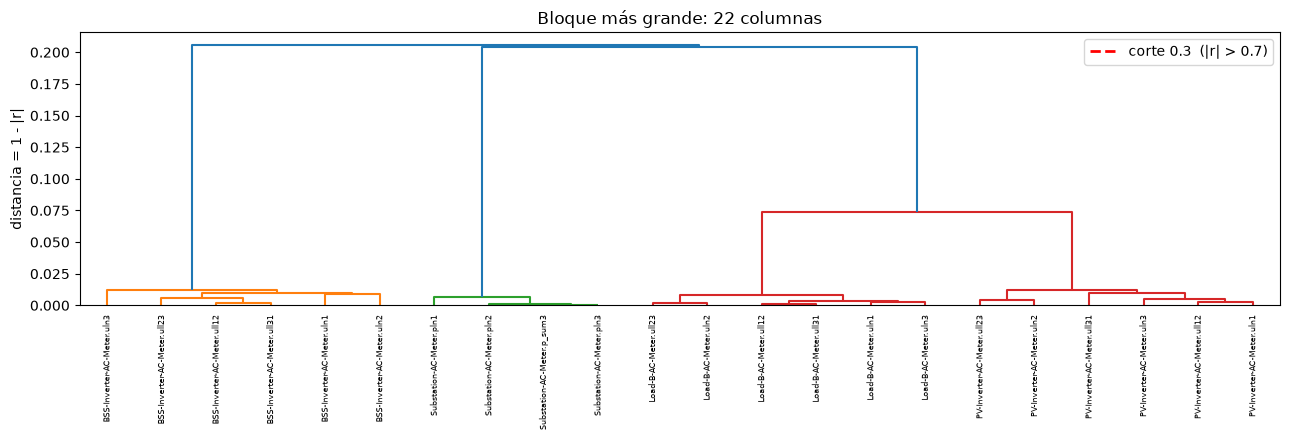

In [22]:
from scipy.cluster.hierarchy import dendrogram

# Repetimos la agrupación, pero solo con las columnas del bloque más grande.
subconjunto = X_entreno[columnas_mas_grande]
correlacion_sub = subconjunto.corr().abs().values
distancia_sub = 1 - correlacion_sub
np.fill_diagonal(distancia_sub, 0)
distancia_sub = (distancia_sub + distancia_sub.T) / 2
arbol_sub = linkage(squareform(distancia_sub, checks=False), method="average")

fig, eje = plt.subplots(figsize=(13, 4.5))
dendrogram(arbol_sub, labels=columnas_mas_grande, ax=eje, leaf_rotation=90, leaf_font_size=6)
eje.axhline(0.3, color="red", linestyle="--", linewidth=2, label="corte 0.3  (|r| > 0.7)")
eje.set_ylabel("distancia = 1 - |r|")
eje.set_title(f"Bloque más grande: {len(columnas_mas_grande)} columnas")
eje.legend()
plt.tight_layout()
plt.show()

varianza acumulada (primeras 5): [0.866 0.934 0.98  0.994 0.998]
componentes para el 95 %: 3


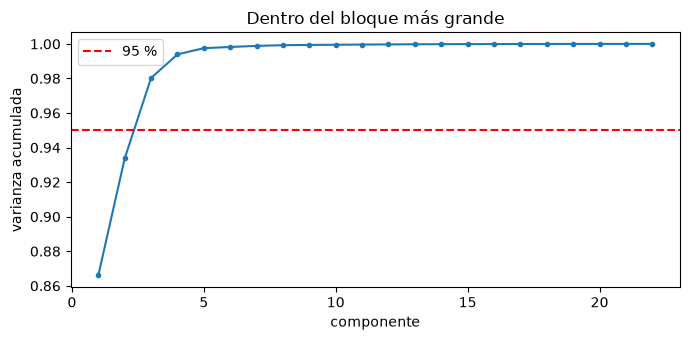

In [23]:
# PASO 5 - Cuántas componentes se queda cada bloque.
# Se estandariza primero porque PCA mide varianza, y las columnas vienen en
# unidades distintas (voltios, amperes, kW). Sin escalar, la de mayor escala
# dominaría la primera componente por unidad y no por información.
subconjunto_estandar = StandardScaler().fit_transform(subconjunto)
pca_bloque = PCA(random_state=42).fit(subconjunto_estandar)
# explained_variance_ratio_ dice qué porción de la varianza del bloque explica
# cada componente; cumsum() las acumula en orden.
varianza_acumulada = pca_bloque.explained_variance_ratio_.cumsum()

print("varianza acumulada (primeras 5):", np.round(varianza_acumulada[:5], 3))
print("componentes para el 95 %:", int(np.searchsorted(varianza_acumulada, 0.95) + 1))

fig, eje = plt.subplots(figsize=(7, 3.5))
eje.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker="o", markersize=3)
eje.axhline(0.95, color="red", linestyle="--", label="95 %")
eje.set_xlabel("componente")
eje.set_ylabel("varianza acumulada")
eje.set_title("Dentro del bloque más grande")
eje.legend()
plt.tight_layout()
plt.show()

Las dos figuras muestran cosas distintas y conviene no mezclarlas:

- El **dendrograma** decide qué columnas van juntas: usa distancias. La línea roja queda por encima de todas las uniones, así que el bloque entra entero.
- El **gráfico de varianza** decide cuántas componentes se queda cada bloque: usa varianza. Acá el 95 % se alcanza con tres componentes porque las 22 columnas del bloque son casi la misma señal (86,6 % + 93,4 % + 98,0 %).

### Qué hace `block_pca()` en la evaluación real

Las celdas de arriba muestran **un solo fold**, para poder leer los bloques con nombre y apellido. En la evaluación LOSO, `src/reduce.py` repite todo ocho veces:

1. Separar entrenamiento y prueba por escenario.
2. Imputar con la mediana del entrenamiento y descartar columnas de varianza nula.
3. Agrupar las columnas (pasos 1 a 4) y hacer PCA dentro de cada grupo (paso 5).
4. Concatenar las componentes de los 24 bloques: en este fold dan **38 columnas**; el promedio de los ocho folds es **37**.
5. Entrenar el clasificador sobre esas columnas y predecir el escenario que quedó afuera.

El resultado medido es AUC **0,901** con Random Forest, la mejor de las ocho variantes que probamos.

Tres advertencias para interpretarlo:

1. El corte 0,70 es un hiperparámetro. Con 0,90 el AUC baja a 0,893 y con 0,95 a 0,882: los bloques se achican y la técnica se parece cada vez más al filtro de correlación.
2. El corte del 95 % es exigente: dos componentes llegan al 93,4 % de la varianza del bloque, así que la tercera es necesaria para pasarlo.
3. La especificidad en `S0` al umbral 0,5 es 0,507, apenas por encima de 0,461 de `physical_corr`. Ambas son pobres: sin `Profile.*`, transferir a un escenario limpio no visto sigue costando falsas alarmas.

Por eso la receta que sigue en producción es `block_pca`: es la que mejor ordena (AUC 0,901) y la que más ataques detecta cuando se permite un 5 % de falsas alarmas (recall 0,527 contra 0,240 de `physical_corr`). El precio queda declarado: sobre el escenario limpio `S0` su especificidad es 0,507. La sección 4.3 de `02_supervisado` y la conclusión vuelven sobre ese intercambio.

### Cuántas columnas deja cada reducción

Cada fila es un camino distinto desde las 132 columnas hasta un conjunto más chico, medido sobre el mismo fold: entrenamiento con todos los escenarios menos `S0`.

Conviene mirar dos cosas a la vez: cuántas columnas deja cada método y en qué punto del camino se reducen. El filtro de correlación aparece dos veces y da resultados muy distintos —55 contra 15— porque en `physical_corr` recibe 25 columnas en lugar de 132. Lo que cambia no es el filtro: es lo que se le da de comer.

In [24]:
# Todas las reducciones en la misma tabla, sobre el mismo fold (S0 afuera).
# Para block_pca hay que sumar las componentes que retiene cada bloque al 95 %.
componentes_bloques = 0
for _, columnas_bloque in bloques.groupby(bloques):
    nombres_bloque = list(columnas_bloque.index)
    if len(nombres_bloque) > 1:
        bloque_escalado = StandardScaler().fit_transform(X_entreno[nombres_bloque])
        componentes_bloques += PCA(n_components=0.95, random_state=42).fit(bloque_escalado).n_components_
    else:
        componentes_bloques += 1

escalera_completa = pd.DataFrame(
    [
        ("sin reducir", X.shape[1], "las 132 tal cual"),
        ("corr", len(corr_filter(X.loc[entreno_sin_s0])), "descarta una columna de cada par con |r| > 0,95"),
        ("physical_corr", len(columnas_s0), "dominio (132 -> 29) + promedio de freq (29 -> 25) + correlación"),
        ("pca", pca_95.n_components_, "PCA global, 95 % de la varianza total"),
        ("block_pca", componentes_bloques, "28 bloques, PCA al 95 % dentro de cada uno"),
        ("rfe", 15, "recursivo: de las 25 físicas elimina de a una hasta 15"),
    ],
    columns=["reducción", "columnas", "cómo llega"],
)
display(escalera_completa)

,reducción,columnas,cómo llega
0,sin reducir,139,las 139 tal cual
1,corr,55,"descarta una columna de cada par con |r| > 0,95"
2,physical_corr,15,dominio (139 -> 29) + promedio de freq (29 -> ...
3,pca,21,"PCA global, 95 % de la varianza total"
4,block_pca,43,"28 bloques, PCA al 95 % dentro de cada uno"
5,rfe,15,recursivo: de las 25 físicas elimina de a una ...


In [25]:
# Qué columnas usa cada reducción, sobre el mismo fold de siempre: entrenamiento
# con todos los escenarios menos S0. Las que eligen columnas muestran sus
# nombres; PCA y block_pca muestran con qué columnas se arma cada componente.
import textwrap

pd.set_option("display.max_colwidth", None)


def mostrar(nombre, columnas, ancho=110):
    '''Imprime una lista de columnas en varias líneas, sin cortar nombres.'''
    print(f"\n{nombre}: {len(columnas)} columnas")
    print(
        textwrap.fill(
            ", ".join(columnas),
            width=ancho,
            initial_indent="  ",
            subsequent_indent="  ",
        )
    )


# --- sin reducir: la matriz de entrada tal cual, agrupada por equipo ---
print(f"sin reducir: {X.shape[1]} columnas (todas las de X)")
conteo_equipos = pd.Series([columna.split(".")[0] for columna in X.columns])
print(conteo_equipos.value_counts().to_string())

# --- corr: descarta una columna de cada par con |r| > 0,95 ---
mostrar("corr", corr_filter(X.loc[entreno_sin_s0]))

# --- physical_corr: dominio + promedio de freq + filtro de correlación ---
mostrar("physical_corr", corr_filter(X_fisico.loc[entreno_sin_s0]))

# --- rfe: de las 25 físicas elimina de a una hasta 15, reajustado en el fold ---
selector_s0 = RFE(
    estimator=crear_pipeline(crear_modelo("rf")),
    n_features_to_select=15,
    step=1,
    importance_getter="named_steps.modelo.feature_importances_",
).fit(
    X_fisico.loc[entreno_sin_s0],
    y.loc[entreno_sin_s0],
    modelo__sample_weight=pesos_balanceados(y.loc[entreno_sin_s0]),
)
mostrar("rfe", list(X_fisico.columns[selector_s0.support_]))

# --- pca: no elige columnas; mezcla las 132 en componentes ---
# Para cada componente, las tres columnas originales con más peso absoluto.
pesos_pca = pd.DataFrame(np.abs(pca_95.components_), columns=X.columns)
principales_pca = pd.DataFrame(
    {
        "componente": range(1, pca_95.n_components_ + 1),
        "columnas con más peso": [
            ", ".join(pesos_pca.iloc[i].nlargest(3).index)
            for i in range(pca_95.n_components_)
        ],
    }
)
print(f"\npca: {pca_95.n_components_} componentes lineales de las 132 columnas")
display(principales_pca)

# --- block_pca: los 28 bloques y las columnas que junta cada uno ---
# Se repite el corte de la sección 1.4 para mostrar el detalle bloque por bloque.
filas_bloques = []
for etiqueta, columnas_bloque in bloques.groupby(bloques):
    nombres_bloque = list(columnas_bloque.index)
    if len(nombres_bloque) > 1:
        estandar = StandardScaler().fit_transform(X_entreno[nombres_bloque])
        componentes = PCA(n_components=0.95, random_state=42).fit(estandar).n_components_
    else:
        componentes = 1
    filas_bloques.append(
        {
            "bloque": etiqueta,
            "de origen": len(nombres_bloque),
            "componentes": componentes,
            "columnas": ", ".join(nombres_bloque),
        }
    )
tabla_bloques = (
    pd.DataFrame(filas_bloques)
    .sort_values("de origen", ascending=False)
    .reset_index(drop=True)
)
print(
    f"\nblock_pca: {tabla_bloques.componentes.sum()} columnas "
    f"desde {len(tabla_bloques)} bloques"
)
# Cada bloque se imprime como "cuántas columnas de origen -> cuántas componentes".
for _, fila in tabla_bloques.iterrows():
    mostrar(
        f"bloque {fila['bloque']} ({fila['de origen']} -> {fila['componentes']})",
        fila["columnas"].split(", "),
    )


sin reducir: 139 columnas (todas las de X)
BSS-Inverter-AC-Meter    26
Load-A-AC-Meter          26
Load-B-AC-Meter          26
PV-Inverter-AC-Meter     26
Substation-AC-Meter      26
Profile                   7
Battery-SOC-Reference     1
Battery-SOC-Reported      1

corr: 55 columnas
  BSS-Inverter-AC-Meter.cos_phi1, BSS-Inverter-AC-Meter.freq, BSS-Inverter-AC-Meter.i_sum3, BSS-Inverter-AC-
  Meter.iln1, BSS-Inverter-AC-Meter.p_sum3, BSS-Inverter-AC-Meter.q_sum3, BSS-Inverter-AC-Meter.qln1, BSS-
  Inverter-AC-Meter.ull12, Battery-SOC-Reference.soc_value, Battery-SOC-Reported.soc_value, Load-A-AC-
  Meter.cos_phi1, Load-A-AC-Meter.cos_phi2, Load-A-AC-Meter.i_sum3, Load-A-AC-Meter.iln1, Load-A-AC-
  Meter.p_sum3, Load-A-AC-Meter.pln1, Load-A-AC-Meter.q_sum3, Load-A-AC-Meter.qln1, Load-A-AC-Meter.qln2,
  Load-A-AC-Meter.qln3, Load-A-AC-Meter.ull12, Load-A-AC-Meter.ull23, Load-A-AC-Meter.ull31, Load-B-AC-
  Meter.cos_phi1, Load-B-AC-Meter.cos_phi2, Load-B-AC-Meter.i_sum3, Load-B-AC-Meter.

,componente,columnas con más peso
0,1,"Substation-AC-Meter.qln3, Substation-AC-Meter.qln1, Substation-AC-Meter.q_sum3"
1,2,"Load-A-AC-Meter.cos_phi3, Load-A-AC-Meter.cos_phi1, Load-A-AC-Meter.ull12"
2,3,"Profile.load2_kw, Load-B-AC-Meter.iln3, Load-B-AC-Meter.iln2"
3,4,"BSS-Inverter-AC-Meter.pln3, BSS-Inverter-AC-Meter.pln2, BSS-Inverter-AC-Meter.p_sum3"
4,5,"Profile.load1_kw, BSS-Inverter-AC-Meter.freq, PV-Inverter-AC-Meter.freq"
5,6,"Load-A-AC-Meter.pln2, Load-A-AC-Meter.pln1, Load-A-AC-Meter.pln3"
6,7,"Substation-AC-Meter.ull12, Substation-AC-Meter.uln1, Substation-AC-Meter.uln3"
7,8,"PV-Inverter-AC-Meter.cos_phi3, PV-Inverter-AC-Meter.cos_phi1, Substation-AC-Meter.iln1"
8,9,"Load-B-AC-Meter.freq, PV-Inverter-AC-Meter.freq, Substation-AC-Meter.freq"
9,10,"BSS-Inverter-AC-Meter.q_sum3, BSS-Inverter-AC-Meter.qln3, Substation-AC-Meter.ull12"



block_pca: 43 columnas desde 28 bloques

bloque 13 (22 -> 3): 22 columnas
  BSS-Inverter-AC-Meter.ull12, BSS-Inverter-AC-Meter.ull23, BSS-Inverter-AC-Meter.ull31, BSS-Inverter-AC-
  Meter.uln1, BSS-Inverter-AC-Meter.uln2, BSS-Inverter-AC-Meter.uln3, Load-B-AC-Meter.ull12, Load-B-AC-
  Meter.ull23, Load-B-AC-Meter.ull31, Load-B-AC-Meter.uln1, Load-B-AC-Meter.uln2, Load-B-AC-Meter.uln3, PV-
  Inverter-AC-Meter.ull12, PV-Inverter-AC-Meter.ull23, PV-Inverter-AC-Meter.ull31, PV-Inverter-AC-Meter.uln1,
  PV-Inverter-AC-Meter.uln2, PV-Inverter-AC-Meter.uln3, Substation-AC-Meter.p_sum3, Substation-AC-Meter.pln1,
  Substation-AC-Meter.pln2, Substation-AC-Meter.pln3

bloque 15 (19 -> 2): 19 columnas
  PV-Inverter-AC-Meter.iln1, PV-Inverter-AC-Meter.iln2, PV-Inverter-AC-Meter.iln3, PV-Inverter-AC-
  Meter.p_sum3, PV-Inverter-AC-Meter.pln1, PV-Inverter-AC-Meter.pln2, PV-Inverter-AC-Meter.pln3, PV-Inverter-
  AC-Meter.q_sum3, PV-Inverter-AC-Meter.qln1, PV-Inverter-AC-Meter.qln2, PV-Inverter-AC-Met

### Qué columnas entrega `block_pca`

`block_pca` no devuelve columnas originales: devuelve una **componente por bloque** (una combinación lineal de las columnas de ese bloque) y deja pasar tal cual los bloques de una sola columna. Por eso la escalera cuenta 43 «columnas»: son 43 salidas del reductor, no 43 nombres del CSV.

La celda ajusta el `BlockPCA` real de `src/reduce.py` con el entrenamiento de este fold (S0 afuera) y muestra cada salida final con las columnas de origen que más pesan y la porción de varianza del bloque que explica.


In [26]:
from src.reduce import BlockPCA

# El reductor real que usa la evaluación LOSO, ajustado con el entrenamiento del fold.
reductor_s0 = BlockPCA(variance=0.95).fit(X.loc[entreno_sin_s0])
print("columnas que entran tras el filtro de varianza:", len(reductor_s0.kept_columns_))

filas_salida_bp = []
for numero_bloque, (nombres_bloque, _, modelo_pca) in enumerate(reductor_s0.blocks_, start=1):
    if modelo_pca is None:
        # Bloque de una sola columna: pasa sin transformar.
        filas_salida_bp.append(
            {
                "columna final": nombres_bloque[0],
                "bloque": numero_bloque,
                "varianza del bloque": np.nan,
                "columnas de origen (peso)": "se conserva tal cual",
            }
        )
        continue
    for j in range(modelo_pca.n_components_):
        pesos = pd.Series(np.abs(modelo_pca.components_[j]), index=nombres_bloque)
        pesos = pesos.sort_values(ascending=False)
        resumen_pesos = ", ".join(
            f"{columna} ({peso:.2f})" for columna, peso in pesos.head(3).items()
        )
        filas_salida_bp.append(
            {
                "columna final": f"bloque {numero_bloque} · comp {j + 1}",
                "bloque": numero_bloque,
                "varianza del bloque": modelo_pca.explained_variance_ratio_[j],
                "columnas de origen (peso)": resumen_pesos,
            }
        )

salida_bp = pd.DataFrame(filas_salida_bp)
print(f"block_pca entrega {len(salida_bp)} columnas al modelo:")
print(f"  componentes: {(salida_bp['varianza del bloque'].notna()).sum()}"
      f" | singletons: {salida_bp['varianza del bloque'].isna().sum()}")
display(salida_bp.round(3))


columnas que entran tras el filtro de varianza: 139
block_pca entrega 43 columnas al modelo:
  componentes: 36 | singletons: 7


,columna final,bloque,varianza del bloque,columnas de origen (peso)
0,bloque 1 · comp 1,1,0.962,"PV-Inverter-AC-Meter.i_sum3 (0.71), Substation-AC-Meter.i_sum3 (0.71)"
1,bloque 2 · comp 1,2,0.985,"Load-B-AC-Meter.freq (0.45), PV-Inverter-AC-Meter.freq (0.45), Load-A-AC-Meter.freq (0.45)"
2,bloque 3 · comp 1,3,0.933,"Substation-AC-Meter.uln3 (0.71), Substation-AC-Meter.ull31 (0.71)"
3,bloque 3 · comp 2,3,0.067,"Substation-AC-Meter.ull31 (0.71), Substation-AC-Meter.uln3 (0.71)"
4,bloque 4 · comp 1,4,0.835,"Substation-AC-Meter.ull12 (0.52), Substation-AC-Meter.uln2 (0.52), Substation-AC-Meter.ull23 (0.49)"
5,bloque 4 · comp 2,4,0.115,"Substation-AC-Meter.uln1 (0.69), Substation-AC-Meter.ull23 (0.57), Substation-AC-Meter.uln2 (0.36)"
6,bloque 4 · comp 3,4,0.043,"Substation-AC-Meter.ull12 (0.57), Substation-AC-Meter.ull23 (0.55), Substation-AC-Meter.uln1 (0.48)"
7,bloque 5 · comp 1,5,0.895,"Load-A-AC-Meter.pln3 (0.38), Load-A-AC-Meter.pln1 (0.38), Load-A-AC-Meter.pln2 (0.38)"
8,bloque 5 · comp 2,5,0.071,"Load-B-AC-Meter.pln3 (0.44), Load-B-AC-Meter.pln1 (0.43), Load-B-AC-Meter.pln2 (0.43)"
9,bloque 6 · comp 1,6,0.910,"Battery-SOC-Reported.soc_value (0.71), Battery-SOC-Reference.soc_value (0.71)"


### Cuánto rinde cada reducción

La escalera contesta *cuántas* columnas quedan. Falta *cuánto rinde* cada camino, con las métricas de la evaluación LOSO y el mismo Random Forest en las seis filas.

Las dos columnas de conteo no coinciden y no es un error. La primera cuenta el fold que venimos usando (todo menos `S0`); la segunda promedia los ocho folds, y en cada uno el filtro de correlación y el corte de los bloques se reajustan con su propio entrenamiento. De ahí que `physical_corr` muestre 10 y 10,4, o `block_pca` 38 y 36,9: el número exacto de columnas depende de qué escenario queda afuera.

Cómo leerla:

- **`corr` es de las mejores.** Con 50 columnas sube el AUC a 0,906 y el recall@5 % a 0,610: descartar la mitad redundante alcanza para superar a las 132 originales.
- **`block_pca` queda a la par.** AUC 0,901 y recall@5 % 0,527, con menos columnas (37) y el mejor recall@1 % (0,359). Sin `Profile.*`, su ventaja sobre el filtro de correlación casi desaparece.
- **`physical_corr` pierde** (0,811): sin las columnas de contexto, la receta física no conserva el desempeño.
- **`pca` es la que más pierde** (0,855): un árbol de decisión no puede cortar una mezcla de 132 columnas.
- **`rfe (física)` confirma la receta sin mejorarla** (0,840).

Ojo con el orden fino: 0,906 contra 0,901 es una diferencia **menor que la variación entre escenarios** de un mismo método. La tabla sirve para descartar caminos, no para coronar un ganador por la cuarta cifra. Mantenemos `block_pca` por ser más compacta y por su recall@1 %, pero `corr` es una alternativa válida y más simple.

In [27]:
# La tabla se lee de resultados/reduccion.csv: mismas 8 rondas LOSO, mismo Random Forest.
tabla_reduccion = pd.read_csv("resultados/reduccion.csv")

comparacion_reducciones = (
    tabla_reduccion[tabla_reduccion.model == "rf"]
    .set_index("reducer")
    .loc[["none", "corr", "physical_corr", "pca", "block_pca"]]
    .drop(columns="model")
    .rename(columns={
        "n_features": "columnas (promedio LOSO)",
        "auc_mean": "AUC",
        "recall_5": "recall@5%",
        "recall_1": "recall@1%",
        "spec_S0": "especificidad S0",
    })
)
comparacion_reducciones.insert(0, "reducción", ["sin reducir", "corr", "physical_corr", "pca", "block_pca"])
# El conteo de un solo fold ya está calculado en `escalera_completa`, en el mismo orden de filas.
# RFE no está en el CSV: se calcula acá, con el mismo protocolo (8 folds LOSO).
fila_rfe = pd.DataFrame(
    [{
        "reducción": "rfe (física)",
        "columnas (promedio LOSO)": loso_rfe.features.mean(),
        "AUC": loso_rfe.AUC.mean(),
        "recall@5%": loso_rfe.recall_5.mean(),
        "recall@1%": loso_rfe.recall_1.mean(),
        "especificidad S0": loso_rfe.especificidad_S0.dropna().iloc[0],
    }]
)
comparacion_reducciones = pd.concat([comparacion_reducciones, fila_rfe], ignore_index=True)

comparacion_reducciones.insert(1, "columnas (este fold)", escalera_completa["columnas"].to_numpy())
comparacion_reducciones = comparacion_reducciones.reset_index(drop=True)[
    [
        "reducción",
        "columnas (este fold)",
        "columnas (promedio LOSO)",
        "AUC",
        "recall@5%",
        "recall@1%",
        "especificidad S0",
    ]
]
display(comparacion_reducciones.round(3))

,reducción,columnas (este fold),columnas (promedio LOSO),AUC,recall@5%,recall@1%,especificidad S0
0,sin reducir,139,139.0,0.912,0.585,0.365,0.943
1,corr,55,55.0,0.941,0.652,0.449,0.718
2,physical_corr,15,15.4,0.943,0.637,0.489,0.996
3,pca,21,20.8,0.873,0.501,0.347,0.388
4,block_pca,43,41.0,0.952,0.752,0.490,0.815
5,rfe (física),15,15.0,0.948,0.668,0.545,1.000


## 2. Una reducción elegida por contexto: `p_sum3`, `q_sum3` y SOC

Un criterio de dominio (lo aportó una persona que conoce el tema) propone quedarse solo con doce columnas:

- `p_sum3` de los cinco dispositivos: la potencia activa total de cada equipo (suma de las tres fases).
- `q_sum3` de los cinco dispositivos: la potencia reactiva total de cada equipo.
- `Battery-SOC-Reference.soc_value` y `Battery-SOC-Reported.soc_value`: el estado de carga de la batería, medido y reportado.

Son magnitudes físicas directas, sin promediar entre medidores: cada una es la señal real de un componente. La pregunta es si esas doce alcanzan para separar ataque de normal y cuánto cambia según se aplique o no la ventana.

Medimos dos variantes del mismo conjunto, con los cuatro modelos y el protocolo LOSO de siempre:

- **sin ventana** (`X_crudo`): las doce columnas tal como vienen del CSV, con su deriva lenta.
- **con ventana** (`X`, rango móvil de 120 s): las mismas doce columnas después de quitar la tendencia, el mismo preprocesado del resto del notebook.

La comparación responde lo mismo que la rama de la ventana (`02a_ventana`): cuánto del rendimiento viene del reloj y cuánto sobrevive al sacarlo. Como siempre, la imputación y el escalado se ajustan solo con el entrenamiento de cada fold, y el `sample_weight` balancea las clases.


In [35]:
# Las doce columnas que pide el criterio de contexto.
medidores = ("BSS-Inverter-AC-Meter", "Load-A-AC-Meter", "Load-B-AC-Meter",
             "PV-Inverter-AC-Meter", "Substation-AC-Meter")
columnas_contexto = (
    [f"{medidor}.p_sum3" for medidor in medidores]
    + [f"{medidor}.q_sum3" for medidor in medidores]
    + ["Battery-SOC-Reference.soc_value", "Battery-SOC-Reported.soc_value"]
)
print(f"columnas de contexto: {len(columnas_contexto)}")
print(columnas_contexto)


def loso_contexto(nombre_modelo, usar_ventana):
    """LOSO sobre las 12 columnas de contexto, con o sin ventana de 120 s."""
    origen = X if usar_ventana else X_crudo

    def armar_datos(retenido):
        test = (escenario == retenido).to_numpy()
        train = ~test
        return (
            origen.loc[train, columnas_contexto],
            origen.loc[test, columnas_contexto],
            y.loc[train],
            y.loc[test].to_numpy(),
        )

    def entrenar(X_train, y_train):
        modelo = crear_pipeline(crear_modelo(nombre_modelo))
        modelo.fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))
        return modelo

    return loso(armar_datos, entrenar)[0]


columnas de contexto: 12
['BSS-Inverter-AC-Meter.p_sum3', 'Load-A-AC-Meter.p_sum3', 'Load-B-AC-Meter.p_sum3', 'PV-Inverter-AC-Meter.p_sum3', 'Substation-AC-Meter.p_sum3', 'BSS-Inverter-AC-Meter.q_sum3', 'Load-A-AC-Meter.q_sum3', 'Load-B-AC-Meter.q_sum3', 'PV-Inverter-AC-Meter.q_sum3', 'Substation-AC-Meter.q_sum3', 'Battery-SOC-Reference.soc_value', 'Battery-SOC-Reported.soc_value']


In [36]:
# Cuatro modelos x {crudo, ventana}: 8 configuraciones, mismas 8 rondas LOSO.
resultados_contexto = {}
for nombre in orden_modelos:
    resultados_contexto[(nombre, "crudo")] = loso_contexto(nombre, usar_ventana=False)
    resultados_contexto[(nombre, "ventana")] = loso_contexto(nombre, usar_ventana=True)


def media_contexto(nombre, ventana, metrica):
    return resultados_contexto[(nombre, ventana)].dropna(subset=["AUC"])[metrica].mean()


def especificidad_s0(nombre, ventana):
    tabla = resultados_contexto[(nombre, ventana)]
    return tabla.loc[tabla["fold"] == "S0", "espec. S0"].iloc[0]


resumen_contexto = pd.DataFrame(
    {
        "modelo": [ETIQUETAS[n] for n in orden_modelos],
        "AUC crudo": [media_contexto(n, "crudo", "AUC") for n in orden_modelos],
        "recall@5% crudo": [media_contexto(n, "crudo", "recall@5%") for n in orden_modelos],
        "recall@1% crudo": [media_contexto(n, "crudo", "recall@1%") for n in orden_modelos],
        "espec. S0 crudo": [especificidad_s0(n, "crudo") for n in orden_modelos],
        "AUC ventana": [media_contexto(n, "ventana", "AUC") for n in orden_modelos],
        "recall@5% ventana": [media_contexto(n, "ventana", "recall@5%") for n in orden_modelos],
        "recall@1% ventana": [media_contexto(n, "ventana", "recall@1%") for n in orden_modelos],
        "espec. S0 ventana": [especificidad_s0(n, "ventana") for n in orden_modelos],
    }
)
display(resumen_contexto.round(3))


,modelo,AUC crudo,recall@5% crudo,recall@1% crudo,espec. S0 crudo,AUC ventana,recall@5% ventana,recall@1% ventana,espec. S0 ventana
0,Random Forest,0.856,0.404,0.284,0.390,0.860,0.479,0.284,0.526
1,SVM (RBF),0.887,0.346,0.203,0.418,0.774,0.327,0.148,0.628
2,XGBoost,0.847,0.419,0.317,0.413,0.850,0.369,0.272,0.518
3,CatBoost,0.804,0.343,0.246,0.409,0.805,0.346,0.222,0.544


## Cierre de la rama

1. La receta física es interpretable pero **pierde**: 0,811 contra 0,880 de base.
2. La selección por importancia también pierde: 0,780.
3. PCA global pierde: 0,855, aunque conserva la dirección de separación.
4. `corr` y `block_pca` **ganan**. Se elige `block_pca` por tamaño y recall@1 %.
5. Las doce columnas de contexto confirman el patrón de la ventana: sin detrend el
   reloj infla el número; con ventana cae a lo esperable.

Volver a la columna vertebral: [`02_supervisado.ipynb`](02_supervisado.ipynb).
Otras ramas: [`02a_ventana.ipynb`](02a_ventana.ipynb),
[`02c_hiperparametros.ipynb`](02c_hiperparametros.ipynb).
